# Clustering I (K-Means)

Clustering adalah metode *unsupervised learning* yang bertujuan mengelompokkan data ke dalam beberapa kelompok (cluster) berdasarkan kemiripan karakteristiknya, tanpa menggunakan label target. Ini berbeda dengan *supervised learning*, di mana algoritma belajar dari data yang sudah diberi label jawaban.

Sederhananya, data yang mirip satu sama lain dikelompokkan ke cluster yang sama, sedangkan data yang berbeda karakteristiknya dipisahkan ke cluster lain. Pengukuran kemiripan ini umumnya didasarkan pada perhitungan jarak, seperti jarak Euclidean, Manhattan, atau Cosine similarity.

**K-Means** adalah salah satu algoritma clustering yang paling populer. Algoritma ini mencoba menemukan K titik pusat (*centroid*) yang paling representatif untuk mewakili kelompok-kelompok data di sekitarnya, lalu setiap titik data bergabung ke pusat terdekatnya.

### 1.1 Install Library

In [ ]:
# pip install pandas numpy matplotlib seaborn scikit-learn

### 1.2. Import Library yang Dibutuhkan

In [8]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.cluster import KMeans 
from sklearn.preprocessing import StandardScaler 
from sklearn.datasets import load_iris, make_moons 
from sklearn.metrics import silhouette_score

### 1.3. Mempersiapkan Dataset
Pertemuan ini menggunakan dataset dari scikit-learn, yaitu dataset **Iris**. Dataset ini berisi data panjang dan lebar sepal serta petal dari tiga jenis bunga Iris.
- #### 1.3.1 Import Dataset

In [9]:
data = pd.read_csv('Mall_Customers.csv')
df = pd.DataFrame(data)
display(df.head())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


- #### 1.3.2 Melihat Informasi Dataset

In [10]:
print(df.describe())
print(df.info())

       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age              

### Memilih Fitur untuk Clustering

In [11]:
df = df.drop(columns=['CustomerID', 'Gender', 'Age'])

- #### 1.3.3 Menyimpan Label Spesies Asli (untuk validasi nanti)

Label spesies asli TIDAK akan digunakan saat proses clustering berlangsung (karena K-Means bersifat *unsupervised*), tetapi akan dipakai nanti pada tahap Interpretasi Hasil untuk membandingkan hasil cluster dengan kelompok aslinya.

In [12]:
display(df.head())

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


### 1.4. Standarisasi Data

K-Means menghitung jarak antar titik data, sehingga semua fitur perlu berada pada skala yang sama sebelum diproses. Gunakan `StandardScaler` dari `sklearn.preprocessing`.

In [13]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)
print(df_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


---
## 2. Menentukan Jumlah Cluster dengan Elbow Method

Karena jumlah cluster optimal (K) tidak diketahui di awal, kita perlu mencoba beberapa nilai K dan menghitung nilai **inertia (WCSS — Within-Cluster Sum of Squares)** untuk masing-masing nilai K tersebut.

Semakin kecil nilai WCSS, semakin rapat/dekat titik-titik data dalam suatu cluster dengan centroid-nya. Namun, WCSS akan selalu menurun seiring bertambahnya K — carilah titik di mana penurunan grafiknya mulai melandai tajam (membentuk pola seperti siku tangan), itulah K optimal.

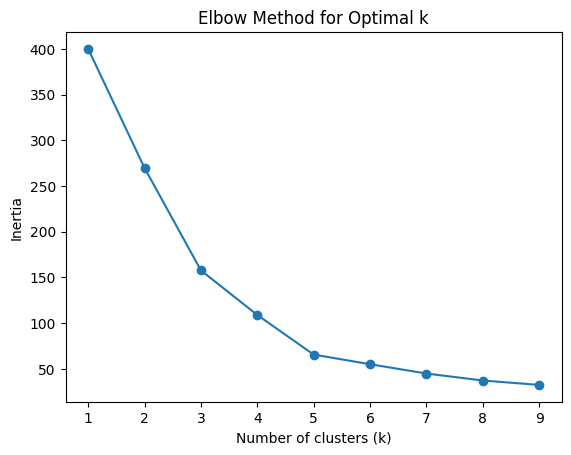

In [15]:
inertia = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

Dari grafik Elbow di atas, tentukan jumlah cluster optimal yang akan dipakai pada langkah berikutnya.
5

---
## 3. Implementasi K-Means

Setelah jumlah cluster (K) dipilih berdasarkan Elbow Method, jalankan algoritma K-Means menggunakan `KMeans` dari `sklearn.cluster`.

**Ingat:**
- Gunakan `n_init=10` untuk mengurangi risiko algoritma terjebak pada solusi lokal yang kurang optimal.
- Gunakan `random_state` agar hasil clustering dapat direproduksi ulang secara konsisten.

In [16]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(df_scaled)
df['cluster'] = labels
display(df.sample(10))

,Annual Income (k$),Spending Score (1-100),cluster
74,54,47,0
94,60,42,0
166,86,20,3
199,137,83,1
115,65,50,0
0,15,39,4
188,103,17,3
193,113,91,1
172,87,10,3
167,86,95,1


---
## 4. Visualisasi Hasil Clustering dengan Scatter Plot

Visualisasikan hasil pengelompokan menggunakan `sns.scatterplot()`, dengan warna (`hue`) berdasarkan label cluster yang baru saja dihasilkan.

**Catatan:** proses clustering dilakukan pada data yang sudah distandarisasi, namun untuk visualisasi sebaiknya gunakan data dalam skala asli agar sumbu lebih mudah dibaca dalam satuan aslinya (cm).

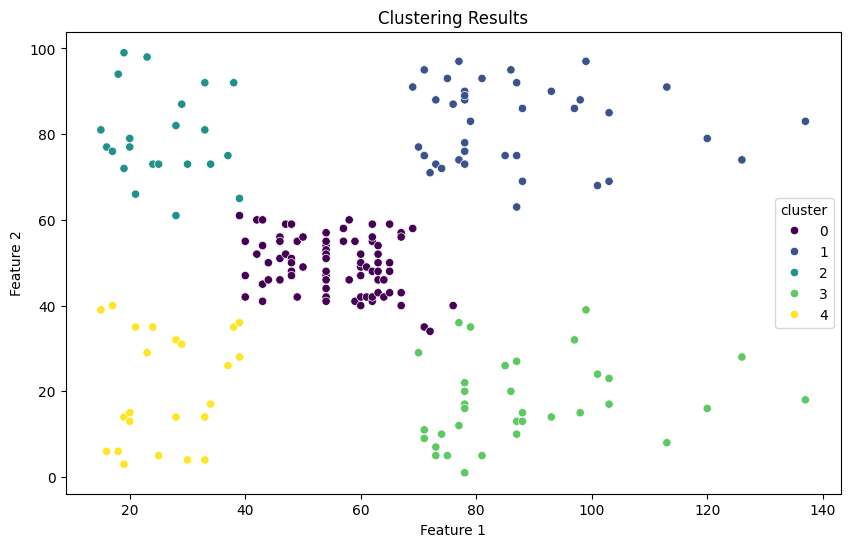

In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df.iloc[:, 0], y=df.iloc[:, 1], hue=df['cluster'], palette='viridis')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Clustering Results')
plt.show()

---
## 5. Evaluasi Cluster dengan Silhouette Score

Selain Elbow Method, kualitas cluster juga bisa dievaluasi menggunakan **Silhouette Score** (`silhouette_score` dari `sklearn.metrics`), yang mengukur seberapa mirip suatu titik dengan cluster-nya sendiri dibandingkan dengan cluster lain terdekat.

Nilai berkisar dari -1 hingga 1:
- Mendekati 1 → titik sangat sesuai dengan cluster-nya
- Mendekati 0 → titik berada di perbatasan antar cluster
- Negatif → titik kemungkinan salah tempat

In [18]:
silhouette_avg = silhouette_score(df_scaled, labels)
print(f'Silhouette Score: {silhouette_avg:.4f}')

Silhouette Score: 0.5547


---
## 6. Interpretasikan karakteristik tiap cluster yang terbentuk

- Misalnya:  cluster  dengan  pendapatan  tinggi  dan  spending  score  tinggi  → segmen pelanggan premium. 
- Berikan nama segmen untuk tiap cluster. 

*(Tuliskan jawaban diskusi kamu di sini)*

---
## 7. Visualisasi Cluster dengan Pairplot

Scatter plot hanya menampilkan 2 fitur sekaligus. Untuk dataset dengan lebih banyak fitur, gunakan `sns.pairplot()` agar semua fitur bisa divisualisasikan berpasangan sekaligus.

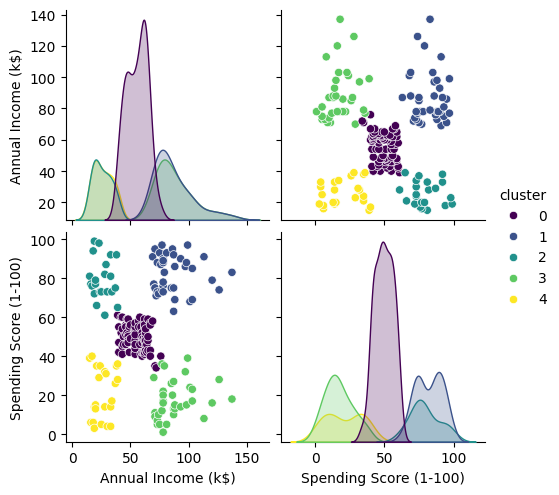

In [19]:
sns.pairplot(df, hue='cluster', palette='viridis', diag_kind='kde')
plt.show()

1. Kluster dengan pendapatan tinggi dan spending score tinggi → segmen pelanggan **premium**.
2. Kluster dengan pendapatan tinggi dan spending score rendah → segmen pelanggan **frugal**.
3. Kluster dengan pendapatan sedang dan spending score sedang → segmen pelanggan **standar**.
4. Kluster dengan pendapatan rendah dan spending score tinggi → segmen pelanggan **impulsif**.
5. Kluster dengan pendapatan rendah dan spending score rendah → segmen pelanggan **minimalis**.

---
## 8. Bukti Keterbatasan K-Means pada Data Non-Spherical (Opsional)

Dataset Iris memiliki cluster yang relatif bulat dan terpisah jelas, sehingga tidak menunjukkan kegagalan K-Means pada bentuk data yang lebih kompleks. Coba terapkan K-Means pada data sintetis berbentuk dua bulan sabit yang saling berkaitan menggunakan `make_moons` dari `sklearn.datasets`, lalu bandingkan bentuk data asli vs hasil clustering K-Means secara visual.

*(Tuliskan kesimpulan kamu: kenapa K-Means gagal membelah data berbentuk bulan sabit ini dengan benar?)*

---
## Catatan Penting Praktikum

- Standardisasi data WAJIB dilakukan sebelum menjalankan K-Means.
- Hasil clustering bisa berbeda jika centroid diinisialisasi secara berbeda; parameter `n_init > 1` membantu mengurangi risiko ini.
- Parameter `random_state` digunakan agar proses acak dapat direproduksi ulang secara konsisten.
- Gunakan metode tambahan (misalnya Silhouette Score) untuk mengevaluasi kualitas cluster.
- K-Means bekerja optimal pada cluster berbentuk bulat (spherical).

---
## 9. Latihan / Studi Kasus Praktikum

**Studi Kasus: Segmentasi Pelanggan Toko Retail**

Link dataset: [Mall Customer Segmentation — Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)

Sebuah pusat perbelanjaan ingin membagi pelanggannya ke dalam beberapa segmen untuk meningkatkan efektivitas strategi pemasaran. Dataset Mall Customers berisi atribut: `CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`.

Dengan menggunakan algoritma K-Means Clustering, lakukan analisis berikut:
1. Baca dataset Mall Customers ke dalam Python dan tampilkan 5 baris pertama.
2. Pilih fitur yang relevan untuk clustering, yaitu `Annual Income (k$)` dan `Spending Score (1-100)`.
3. Lakukan standarisasi data sebelum diterapkan ke K-Means.
4. Tentukan jumlah cluster optimal dengan menggunakan Elbow Method.
5. Terapkan K-Means Clustering pada dataset dengan jumlah cluster hasil Elbow Method.
6. Visualisasikan hasil clustering dalam bentuk scatter plot dengan warna berbeda untuk tiap cluster.
7. Interpretasikan karakteristik tiap cluster yang terbentuk (misalnya: cluster dengan pendapatan tinggi dan spending score tinggi → segmen pelanggan premium).
8. Berikan nama segmen untuk tiap cluster.
9. Buat rekomendasi strategi pemasaran berdasarkan hasil clustering.

### Rekomendasi strategi pemasaran bisa berupa:
- **Kluster pelanggan premium**: Tawarkan produk eksklusif atau layanan VIP untuk meningkatkan loyalitas mereka, undang mereka secara privat ke acara ekslusif seperti peluncuran produk baru.
- **Kluster pelanggan frugal**: Terapkan strategi cross-selling yang halus. Karena mereka hanya membeli apa yang mereka butuhkan, buat displai produk pelengkap yang sangat dekat dengan produk utama yang mereka cari.
- **Kluster pelanggan standar**: Buat program loyalitas pelanggan yang memberikan diskon atau hadiah bagi pelanggan yang semakin sering berbelanja.
- **Kluster pelanggan impulsif**: Buat promosi flash sale atau diskon mendadak untuk menarik perhatian mereka.
- **Kluster pelanggan minimalis**: Penawaran khusus berupa disediakan tenant yang menjual produk mikro berharga murah yang ditempatkan di area strategis serta diberikan promosi seperti 'Beli 1 gratis 1'.